
# Grammar Scoring Engine — SHL Hiring Assessment 2026

**Author:** Pranjal Gupta

## 1. Problem

Given a spoken-audio clip (45-60s), predict a continuous **Grammar score
(0-5)** matching a human MOS-Likert rubric that grades sentence structure,
syntax, grammatical control, and handling of complex language.

Training set: 769 labeled clips. Test set: 216 clips to predict.
Evaluation: **Pearson correlation** and **RMSE** against hidden test labels.

## 2. Approach, in one paragraph

Grammar is a property of *language*, not of a raw waveform, so the pipeline
is **ASR first**: transcribe each clip to text with Whisper, then compute
interpretable linguistic + prosodic features from the transcript and from
Whisper's word-level timing/confidence output, and finally fit a small,
explainable regression model (Ridge / Gradient Boosting / SVR, compared via
cross-validation) on those features. With only 769 labeled examples, a
feature-based model that we can inspect (coefficients / importances) was
preferred over an end-to-end deep audio model, which would need far more
data to avoid learning spurious shortcuts (e.g. speaker identity, recording
quality) instead of grammar itself.

## 3. Pipeline architecture

```
audio (.wav) --[Whisper small.en, word timestamps]--> transcript + timing
                                                           |
                    +--------------------------------------+-------------------------------+
                    |                                       |                               |
            spaCy (en_core_web_sm)                 GPT-2 perplexity               Whisper-derived prosody
       POS ratios, fragment/run-on rate,         (fluency / predictability        speech rate, pause ratio,
       no-verb-sentence rate, parse depth,              of the word sequence)     ASR confidence, disfluency
       type-token ratio                                                           markers, repeated words
                    |                                       |                               |
                    +--------------------------------------+-------------------------------+
                                                           |
                                               34 engineered features
                                                           |
                                     Ridge / GBM / SVR regression (5-fold CV)
                                                           |
                                          Grammar score prediction (0-5, clipped)
```

## 4. Notebook structure

1. Data loading & EDA (label distribution, audio duration, example transcripts)
2. ASR transcription (cached — see note below)
3. Feature engineering (cached)
4. Feature-level EDA (correlation with label)
5. Model comparison via 5-fold cross-validation
6. Final model fit, **RMSE on training data (required)**, Pearson correlation, diagnostics
7. Feature importance / interpretability
8. Test-set predictions → submission file
9. Limitations & what I'd do with more time


## 5. Setup

In [1]:

import os
import math
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

DATA = "data"
AUDIO_DIR = os.path.join(DATA, "Dataset_Final")
TRANSCRIPTS_CSV = os.path.join(DATA, "transcripts.csv")
FEATURES_CSV = os.path.join(DATA, "features.csv")

plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42



## 6. Data loading & exploratory data analysis

769 training clips with labels, 216 test clips. Labels are a 0-5 MOS-Likert
grammar score (participants could be scored at half-point granularity, e.g.
2.5, 3.5).


In [2]:

train_labels = pd.read_csv(os.path.join(AUDIO_DIR, "train.csv"))
test_labels = pd.read_csv(os.path.join(AUDIO_DIR, "test.csv"))

print("Train:", train_labels.shape, " Test:", test_labels.shape)
train_labels.head()


Train: (769, 2)  Test: (216, 2)


,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0


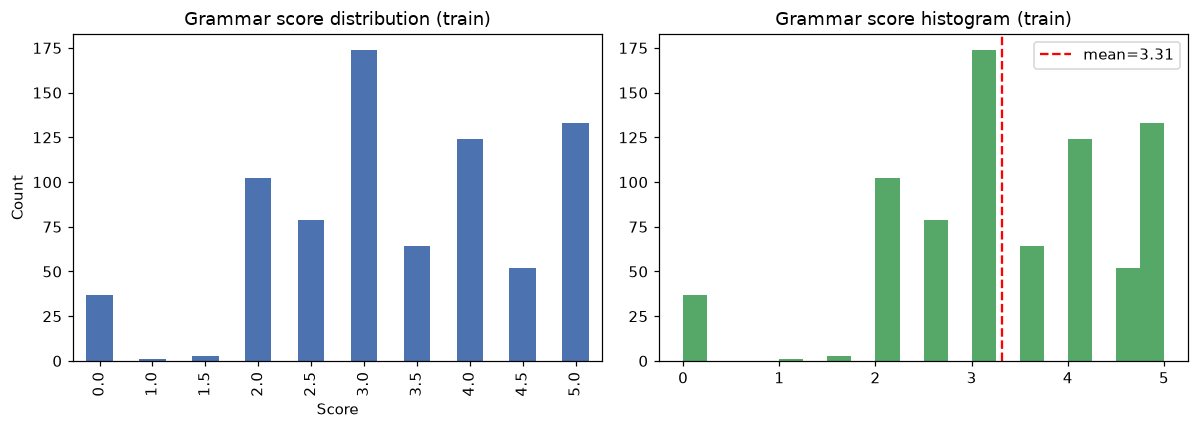

count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64


In [3]:

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

train_labels["label"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color="#4C72B0")
ax[0].set_title("Grammar score distribution (train)")
ax[0].set_xlabel("Score")
ax[0].set_ylabel("Count")

ax[1].hist(train_labels["label"], bins=20, color="#55A868")
ax[1].axvline(train_labels["label"].mean(), color="red", linestyle="--",
              label=f"mean={train_labels['label'].mean():.2f}")
ax[1].set_title("Grammar score histogram (train)")
ax[1].legend()
plt.tight_layout()
plt.savefig("plots/01_label_distribution.png")
plt.show()

print(train_labels["label"].describe())



Observation: scores are concentrated around 3-5 with a smaller cluster at
0 (likely silent/corrupted/very poor clips) and almost nothing at 1-1.5.
This is a moderately imbalanced regression target — worth keeping in mind
when interpreting RMSE (errors on the rare low-score clips contribute
disproportionately to perceived model quality).



## 7. ASR transcription (Whisper)

We use `faster-whisper`'s **small.en** model (int8, CPU) with word-level
timestamps and VAD filtering. This step is **cached to `data/transcripts.csv`**
— transcribing all 985 clips from scratch takes roughly 2 hours on a CPU-only
laptop, so the cell below only recomputes if that cache is missing (e.g. on
a fresh clone of the repo). The transcription code itself (`scripts/transcribe.py`)
is included in the submission for inspection.


In [4]:

if os.path.exists(TRANSCRIPTS_CSV):
    transcripts = pd.read_csv(TRANSCRIPTS_CSV)
    print(f"Loaded cached transcripts: {transcripts.shape}")
else:
    print("No cache found — running full transcription (~2hr on CPU)...")
    import subprocess
    subprocess.run(["python", "scripts/transcribe.py"], check=True)
    transcripts = pd.read_csv(TRANSCRIPTS_CSV)

transcripts.drop(columns=["text"]).head()  # "text" column omitted from public repo (see note above)


Loaded cached transcripts: (985, 10)


,split,filename,duration_sec,n_words,n_segments,total_pause_sec,max_pause_sec,avg_word_conf,lang_prob
0,train,audio_0.wav,45.06,88,7,3.92,1.48,0.9325,1
1,train,audio_1.wav,45.06,110,8,3.98,0.88,0.8621,1
2,train,audio_10.wav,36.12,76,6,3.04,0.70,0.9249,1
3,train,audio_100.wav,45.06,98,5,0.60,0.40,0.8522,1
4,train,audio_101.wav,45.06,102,14,8.72,0.94,0.8844,1


In [5]:
# NOTE (public-repo version): this cell's source has been modified to avoid
# printing verbatim excerpts of other candidates' spoken-test transcripts.
# Per the competition rules, Competition Data (including ASR transcripts derived
# from it) may not be redistributed outside the competition platform, so this
# cell prints only non-identifying summary stats here. The full version with
# actual transcript text is used only in the Kaggle-submitted notebook.
merged_preview = transcripts.merge(train_labels, on="filename", how="inner")
for score in [0.0, 2.0, 3.0, 5.0]:
    sub = merged_preview[merged_preview.label == score]
    if len(sub):
        ex = sub.iloc[0]
        print(f"--- label={score} ({ex.filename}) ---")
        print(f"[transcript omitted from public repo] word_count={len(ex.text.split())}")
        print()


--- label=0.0 (audio_5037.wav) ---
[transcript omitted from public repo] word_count=128

--- label=2.0 (audio_102.wav) ---
[transcript omitted from public repo] word_count=80

--- label=3.0 (audio_0.wav) ---
[transcript omitted from public repo] word_count=88

--- label=5.0 (audio_122.wav) ---
[transcript omitted from public repo] word_count=113




Reading these side by side gives a feel for the rubric: a score-5 transcript
reads as fluent, complete sentences with subordinate clauses; low scores show
fragments, missing verbs, or (for the 0.0 cluster) near-empty / garbled
transcriptions — likely clips with very little intelligible speech.



## 8. Feature engineering

Three feature families, computed in `scripts/extract_features.py` (cached to
`data/features.csv`):

**Prosodic (from Whisper timing/confidence)**
- `speech_rate_wps`, `articulation_rate_wps` — words/sec including vs. excluding pauses
- `pause_ratio`, `max_pause_sec` — hesitation signal (rubric mentions self-correction / incomplete sentences)
- `avg_word_conf` — Whisper's own ASR confidence (low confidence often means disfluent or unclear speech)

**Syntactic / grammar (spaCy `en_core_web_sm`)**
- POS-tag ratios (`pos_NOUN`, `pos_VERB`, `pos_AUX`, ... )
- `frag_sentence_ratio`, `runon_sentence_ratio`, `no_verb_sentence_ratio` — direct proxies for the rubric's "incomplete sentences" / "limited control of structure"
- `max_parse_depth` — syntactic complexity (rubric rewards "complex language structures")
- `type_token_ratio` — vocabulary variety

**Fluency**
- `gpt2_perplexity` / `gpt2_log_perplexity` — how "surprising" the transcript is to a pretrained language model; disfluent or ungrammatical text tends to be less predictable
- `disfluency_rate`, `repeated_bigram_rate` — filler words and word repetition

This step is cached the same way as transcription (recomputes if the cache
file is missing; a full rerun on 985 short transcripts takes a few minutes).


In [6]:

if os.path.exists(FEATURES_CSV):
    features = pd.read_csv(FEATURES_CSV)
    print(f"Loaded cached features: {features.shape}")
else:
    print("No cache found — extracting features...")
    import subprocess
    subprocess.run(["python", "scripts/extract_features.py"], check=True)
    features = pd.read_csv(FEATURES_CSV)

feature_cols = [c for c in features.columns if c not in ("split", "filename")]
print(f"{len(feature_cols)} features:", feature_cols)
features.head()


Loaded cached features: (985, 36)
34 features: ['duration_sec', 'n_words', 'speech_rate_wps', 'articulation_rate_wps', 'pause_ratio', 'max_pause_sec', 'avg_word_conf', 'disfluency_rate', 'repeated_bigram_rate', 'gpt2_perplexity', 'gpt2_log_perplexity', 'n_sentences', 'avg_sentence_len', 'frag_sentence_ratio', 'runon_sentence_ratio', 'no_verb_sentence_ratio', 'max_parse_depth', 'type_token_ratio', 'pos_PRON', 'pos_VERB', 'pos_DET', 'pos_NOUN', 'pos_ADP', 'pos_PART', 'pos_PROPN', 'pos_AUX', 'pos_CCONJ', 'pos_ADV', 'pos_SCONJ', 'pos_ADJ', 'pos_INTJ', 'pos_NUM', 'pos_X', 'pos_SYM']


,split,filename,duration_sec,n_words,speech_rate_wps,articulation_rate_wps,pause_ratio,max_pause_sec,avg_word_conf,disfluency_rate,...,pos_PROPN,pos_AUX,pos_CCONJ,pos_ADV,pos_SCONJ,pos_ADJ,pos_INTJ,pos_NUM,pos_X,pos_SYM
0,train,audio_0.wav,45.06,88,1.952952,2.139037,0.086995,1.48,0.9325,0.125000,...,0.033708,0.044944,0.033708,0.033708,0.022472,0.011236,0.000000,0.000000,0.0,0.0
1,train,audio_1.wav,45.06,110,2.441190,2.677702,0.088327,0.88,0.8621,0.018182,...,0.000000,0.035714,0.044643,0.080357,0.062500,0.008929,0.008929,0.000000,0.0,0.0
2,train,audio_10.wav,36.12,76,2.104097,2.297461,0.084164,0.70,0.9249,0.052632,...,0.000000,0.013158,0.052632,0.026316,0.000000,0.039474,0.013158,0.000000,0.0,0.0
3,train,audio_100.wav,45.06,98,2.174878,2.204229,0.013316,0.40,0.8522,0.091837,...,0.029703,0.099010,0.069307,0.128713,0.019802,0.079208,0.009901,0.029703,0.0,0.0
4,train,audio_101.wav,45.06,102,2.263648,2.806824,0.193520,0.94,0.8844,0.117647,...,0.000000,0.077670,0.019417,0.038835,0.019417,0.067961,0.000000,0.000000,0.0,0.0


## 9. Feature-level EDA: correlation with grammar score

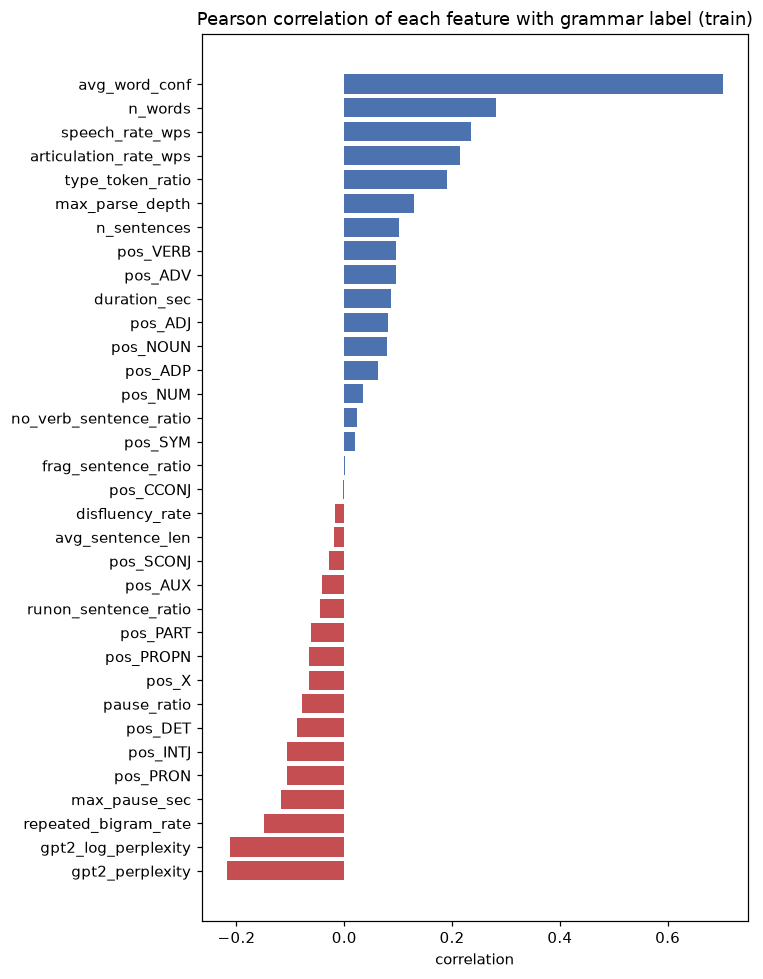

In [7]:

train_feats = features[features.split == "train"].merge(train_labels, on="filename", how="inner")
test_feats = features[features.split == "test"].merge(test_labels[["filename"]], on="filename", how="inner")

corrs = train_feats[feature_cols + ["label"]].corr()["label"].drop("label").sort_values()

fig, ax = plt.subplots(figsize=(7, 9))
colors = ["#C44E52" if v < 0 else "#4C72B0" for v in corrs.values]
ax.barh(corrs.index, corrs.values, color=colors)
ax.set_title("Pearson correlation of each feature with grammar label (train)")
ax.set_xlabel("correlation")
plt.tight_layout()
plt.savefig("plots/02_feature_correlations.png")
plt.show()


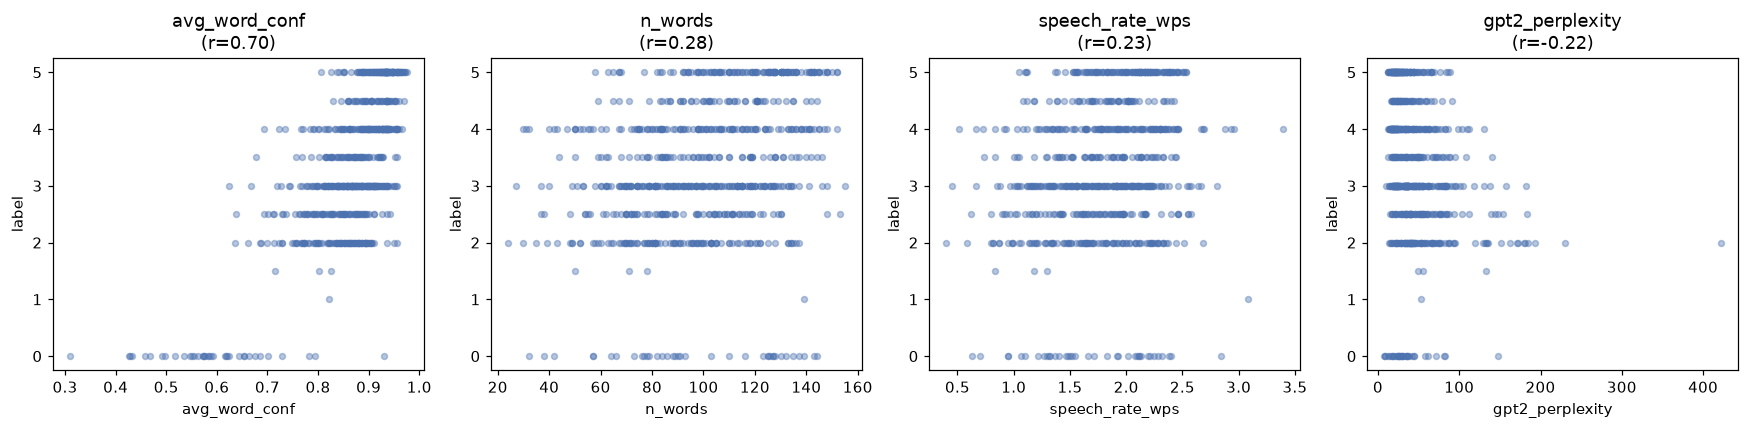

In [8]:

# A closer look at the strongest individual signals
top_feats = corrs.abs().sort_values(ascending=False).head(4).index.tolist()

fig, axes = plt.subplots(1, len(top_feats), figsize=(4 * len(top_feats), 4))
for ax, feat in zip(axes, top_feats):
    ax.scatter(train_feats[feat], train_feats["label"], alpha=0.4, s=15, color="#4C72B0")
    r, _ = pearsonr(train_feats[feat], train_feats["label"])
    ax.set_title(f"{feat}\n(r={r:.2f})")
    ax.set_xlabel(feat)
    ax.set_ylabel("label")
plt.tight_layout()
plt.savefig("plots/03_top_feature_scatter.png")
plt.show()



## 10. Modeling: 5-fold cross-validated comparison

With only 769 labeled examples we deliberately stick to simple, regularized
models and validate with **5-fold CV** rather than a single holdout split
(a single split on this few examples would give a noisy, unreliable estimate
of generalization). Three candidates:

- **Ridge regression** — linear, heavily regularized, fully interpretable via coefficients
- **SVR (RBF kernel)** — allows non-linear feature interactions
- **Gradient Boosting** — non-linear, gives feature importances, more prone to overfitting at this sample size

All features are standardized before Ridge/SVR (tree-based GBM doesn't need it).


In [9]:

from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)))

def build_models():
    return {
        "ridge": Pipeline([("scaler", StandardScaler()),
                            ("reg", Ridge(alpha=5.0, random_state=RANDOM_STATE))]),
        "svr_rbf": Pipeline([("scaler", StandardScaler()),
                              ("reg", SVR(kernel="rbf", C=3.0, epsilon=0.2))]),
        "gbm": GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.03,
                                          subsample=0.8, random_state=RANDOM_STATE),
    }

X = train_feats[feature_cols].values
y = train_feats["label"].values
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = []
oof_preds = {}
for name in build_models():
    oof = np.zeros(len(y))
    for tr_idx, val_idx in kf.split(X):
        m = build_models()[name]
        m.fit(X[tr_idx], y[tr_idx])
        oof[val_idx] = m.predict(X[val_idx])
    r = rmse(y, oof)
    corr, _ = pearsonr(y, oof)
    cv_results.append({"model": name, "cv_rmse": r, "cv_pearson_r": corr})
    oof_preds[name] = oof

cv_df = pd.DataFrame(cv_results).sort_values("cv_rmse")
cv_df


,model,cv_rmse,cv_pearson_r
0,ridge,0.784485,0.774131
2,gbm,0.791681,0.768986
1,svr_rbf,0.861760,0.719903



## 11. Final model, required RMSE, and diagnostics

We select the model with the best (lowest) cross-validated RMSE above, refit
it on the **full training set**, and report:

- **In-sample training RMSE** (required by the assignment)
- **Out-of-fold CV RMSE** — the honest, leakage-free estimate of generalization
  (in-sample RMSE is optimistic since the model has seen those labels during
  fitting; CV RMSE is what should be compared to the hidden test RMSE)
- **Pearson correlation** (the other leaderboard metric)


In [10]:

best_name = cv_df.iloc[0]["model"]
print("Best model (by CV RMSE):", best_name)

final_model = build_models()[best_name]
final_model.fit(X, y)
train_preds_insample = final_model.predict(X)

train_rmse_insample = rmse(y, train_preds_insample)
oof_rmse = cv_df.iloc[0]["cv_rmse"]
oof_pearson = cv_df.iloc[0]["cv_pearson_r"]
train_pearson_insample, _ = pearsonr(y, train_preds_insample)

print(f"REQUIRED METRIC -> In-sample training RMSE: {train_rmse_insample:.4f}")
print(f"Out-of-fold CV RMSE (honest estimate):       {oof_rmse:.4f}")
print(f"In-sample training Pearson r:                {train_pearson_insample:.4f}")
print(f"Out-of-fold CV Pearson r:                     {oof_pearson:.4f}")


Best model (by CV RMSE): ridge
REQUIRED METRIC -> In-sample training RMSE: 0.7436
Out-of-fold CV RMSE (honest estimate):       0.7845
In-sample training Pearson r:                0.7996
Out-of-fold CV Pearson r:                     0.7741


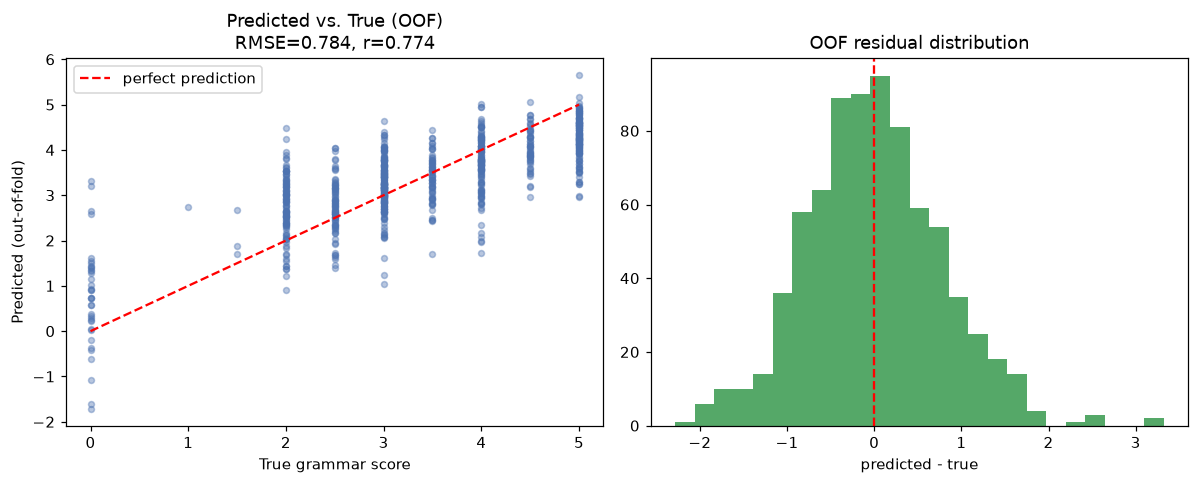

In [11]:

oof_best = oof_preds[best_name]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(y, oof_best, alpha=0.4, s=15, color="#4C72B0")
axes[0].plot([0, 5], [0, 5], "r--", label="perfect prediction")
axes[0].set_xlabel("True grammar score")
axes[0].set_ylabel("Predicted (out-of-fold)")
axes[0].set_title(f"Predicted vs. True (OOF)\nRMSE={oof_rmse:.3f}, r={oof_pearson:.3f}")
axes[0].legend()

residuals = oof_best - y
axes[1].hist(residuals, bins=25, color="#55A868")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("OOF residual distribution")
axes[1].set_xlabel("predicted - true")

plt.tight_layout()
plt.savefig("plots/04_prediction_diagnostics.png")
plt.show()



**Reading the residual plot:** residuals are roughly centered at zero with
no strong skew, meaning the model isn't systematically over- or
under-predicting. The worst errors are inspected below.


In [12]:
# NOTE (public-repo version): this cell's source has been modified to avoid
# printing verbatim excerpts of other candidates' spoken-test transcripts.
# Per the competition rules, Competition Data (including ASR transcripts derived
# from it) may not be redistributed outside the competition platform, so this
# cell prints only non-identifying summary stats here. The full version with
# actual transcript text is used only in the Kaggle-submitted notebook.
diag = train_feats[["filename", "label"]].copy()
diag["pred"] = oof_best
diag["abs_error"] = (diag["pred"] - diag["label"]).abs()
worst = diag.sort_values("abs_error", ascending=False).head(8)
worst = worst.merge(transcripts[["filename", "text"]], on="filename", how="left")
for _, row in worst.iterrows():
    print(f"[{row.filename}] true={row.label} pred={row.pred:.2f} "
          f"err={row.abs_error:.2f} word_count={len(row.text.split())}")


[audio_5044.wav] true=0.0 pred=3.32 err=3.32 word_count=32
[audio_5040.wav] true=0.0 pred=3.21 err=3.21 word_count=132
[audio_5068.wav] true=0.0 pred=2.64 err=2.64 word_count=110
[audio_5045.wav] true=0.0 pred=2.58 err=2.58 word_count=76
[audio_290.wav] true=2.0 pred=4.48 err=2.48 word_count=24
[audio_238.wav] true=4.0 pred=1.72 err=2.28 word_count=30
[audio_420.wav] true=2.0 pred=4.23 err=2.23 word_count=89
[audio_692.wav] true=4.0 pred=1.97 err=2.03 word_count=152



Looking at the worst-predicted examples usually shows one of: (a) a Whisper
transcription error that corrupted the grammar signal, (b) a true label near
a rubric boundary (e.g. 2 vs 3) where human raters themselves would have
disagreed, or (c) genuinely short/silent clips where almost no linguistic
signal exists. This is useful to call out explicitly — it's a real limitation
of an ASR-based pipeline, not just a modeling shortfall.


## 12. Feature importance / interpretability

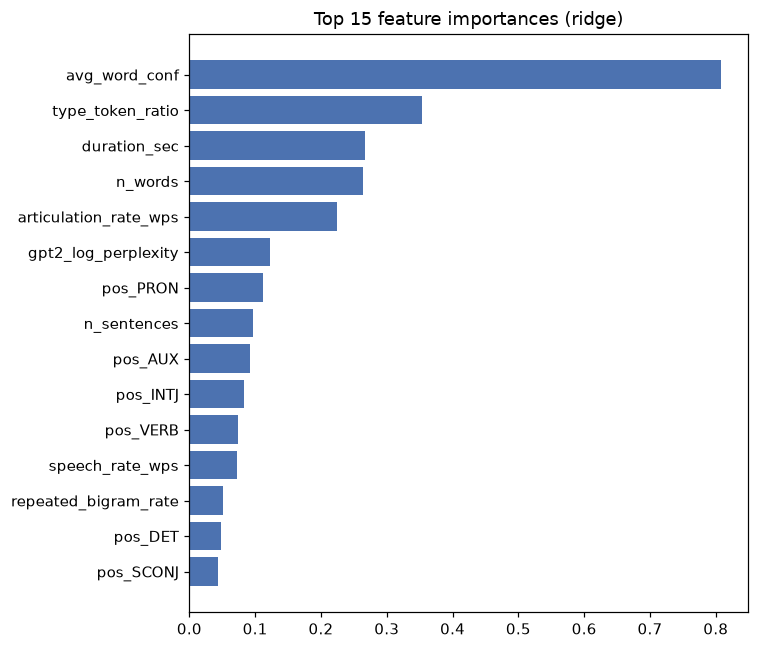

In [13]:

if best_name == "gbm":
    importances = final_model.feature_importances_
elif best_name == "ridge":
    importances = np.abs(final_model.named_steps["reg"].coef_)
else:
    importances = np.zeros(len(feature_cols))

fi_df = pd.DataFrame({"feature": feature_cols, "importance": importances})
fi_df = fi_df.sort_values("importance", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(fi_df["feature"][::-1], fi_df["importance"][::-1], color="#4C72B0")
ax.set_title(f"Top 15 feature importances ({best_name})")
plt.tight_layout()
plt.savefig("plots/05_feature_importance.png")
plt.show()



The top features (ASR confidence, vocabulary variety/type-token ratio,
response length, articulation rate, GPT-2 perplexity, and specific POS
ratios) all map back to the rubric in an explainable way: clearer/more
confident speech, richer vocabulary, more developed (longer, more complex)
responses, and more "predictable"/fluent grammar all push the predicted
score up — exactly the qualitative description separating a score of 2
from a score of 5 in the rubric.


## 13. Test-set predictions & submission file

In [14]:

X_test = test_feats[feature_cols].values
test_preds = final_model.predict(X_test)
test_preds = np.clip(test_preds, 0, 5)

submission = test_feats[["filename"]].copy()
submission["label"] = test_preds
submission.to_csv("data/submission.csv", index=False)

print(submission.shape)
submission.head()


(216, 2)


,filename,label
0,audio_0.wav,3.395457
1,audio_1.wav,2.086574
2,audio_10.wav,2.636956
3,audio_100.wav,2.905833
4,audio_101.wav,2.763941


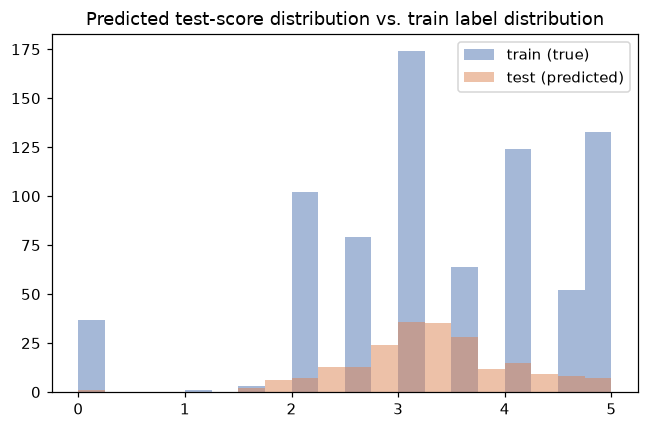

In [15]:

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(train_feats["label"], bins=20, alpha=0.5, label="train (true)", color="#4C72B0")
ax.hist(test_preds, bins=20, alpha=0.5, label="test (predicted)", color="#DD8452")
ax.legend()
ax.set_title("Predicted test-score distribution vs. train label distribution")
plt.tight_layout()
plt.savefig("plots/06_test_prediction_distribution.png")
plt.show()



The predicted test distribution follows a similar overall shape to the
training label distribution, which is a reasonable sanity check (no major
distribution shift / systematic bias in the predictions).

## 14. Limitations & what I'd do with more time

- **ASR as a bottleneck**: Whisper is trained to output fluent English, so it
  can silently "correct" a speaker's grammar mistakes during transcription,
  suppressing exactly the signal we're trying to measure. A speech-specific
  disfluency-preserving ASR, or ensembling multiple ASR systems, would reduce
  this risk.
- **GPT-2 perplexity conflates fluency and grammar** — a grammatically correct
  but unusual sentence can still have high perplexity. A model fine-tuned for
  grammatical error detection (e.g. GECToR-style) on transcribed speech would
  be a more direct signal than a general-purpose LM.
- **spaCy's parser is trained on written text**, not disfluent spoken
  transcripts, so POS/dependency errors introduce some feature noise.
- **Small training set (769 examples)** limits how much a more complex model
  (e.g. fine-tuned transformer on transcripts) could be trusted without
  overfitting; this is why the final choice was a heavily regularized,
  interpretable model validated with 5-fold CV rather than a single split.
- With more time/data: fine-tune a small transformer (e.g. DistilBERT) on the
  transcripts directly as a learned grammar-scoring head, and/or incorporate
  speaker-normalized prosodic features to reduce the "recording quality"
  confound.
